# Visão geral das noites

Atualizar os dados antes de rodar:

```bash
uv run sleep-ingest D:   # backup do cartão
uv run sleep-build       # EDF -> Parquet
```

Tabelas disponíveis no DuckDB: `nights`, `sessions`, `events`, `signals_2s`.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from sleep_analysis.db import connect
from sleep_analysis.study import label_period, load_study

db = connect()
study = load_study()

nights = db.sql("SELECT * FROM nights ORDER BY night").df()
nights["period"] = label_period(nights, study)
print(f"{len(nights)} noites de {nights['night'].min():%d/%m/%Y} a {nights['night'].max():%d/%m/%Y}")

308 noites de 16/09/2025 a 22/09/2026


## Resumo por mês

A pressão e a umidade mudaram ao longo do tempo; comparações justas devem olhar noites com a mesma pressão.

In [2]:
db.sql("""
    SELECT
        strftime(night, '%Y-%m') AS month,
        count(*) AS nights,
        round(avg(usage_hours), 1) AS usage_hours,
        round(avg(ahi), 2) AS ahi,
        round(avg(oai), 2) AS obstructive_index,
        round(avg(cai), 2) AS central_index,
        round(avg(hi), 2) AS hypopnea_index,
        round(avg(leak_95_l_min), 1) AS leak_95_l_min,
        round(avg(pressure), 1) AS pressure,
        round(avg(humidity_level), 1) AS humidity_level,
        round(avg(mask_events), 1) AS mask_events
    FROM nights
    GROUP BY 1
    ORDER BY 1
""").df()

,month,nights,usage_hours,ahi,obstructive_index,central_index,hypopnea_index,leak_95_l_min,pressure,humidity_level,mask_events
0,2025-09,12,6.4,0.73,0.28,0.13,0.28,1.7,5.8,3.0,2.5
1,2025-10,31,7.7,0.62,0.12,0.14,0.33,5.6,5.8,3.0,2.1
2,2025-11,30,8.1,0.87,0.21,0.16,0.47,3.6,6.3,3.9,2.4
3,2025-12,11,6.3,0.59,0.05,0.26,0.25,2.1,7.7,4.7,2.5
4,2026-01,22,6.8,0.55,0.12,0.14,0.26,1.4,8.0,4.2,2.5
5,2026-02,28,6.9,0.63,0.12,0.12,0.34,4.4,8.0,4.0,2.1
6,2026-03,30,6.5,0.39,0.11,0.13,0.12,7.1,8.8,4.0,2.2
7,2026-04,25,7.6,0.61,0.18,0.14,0.24,6.6,7.9,3.0,2.4
8,2026-05,28,7.8,0.51,0.17,0.08,0.24,4.5,7.5,3.3,2.2
9,2026-06,14,7.0,0.67,0.29,0.05,0.29,0.5,7.5,4.0,2.3


## Tendências (média móvel de 7 noites)

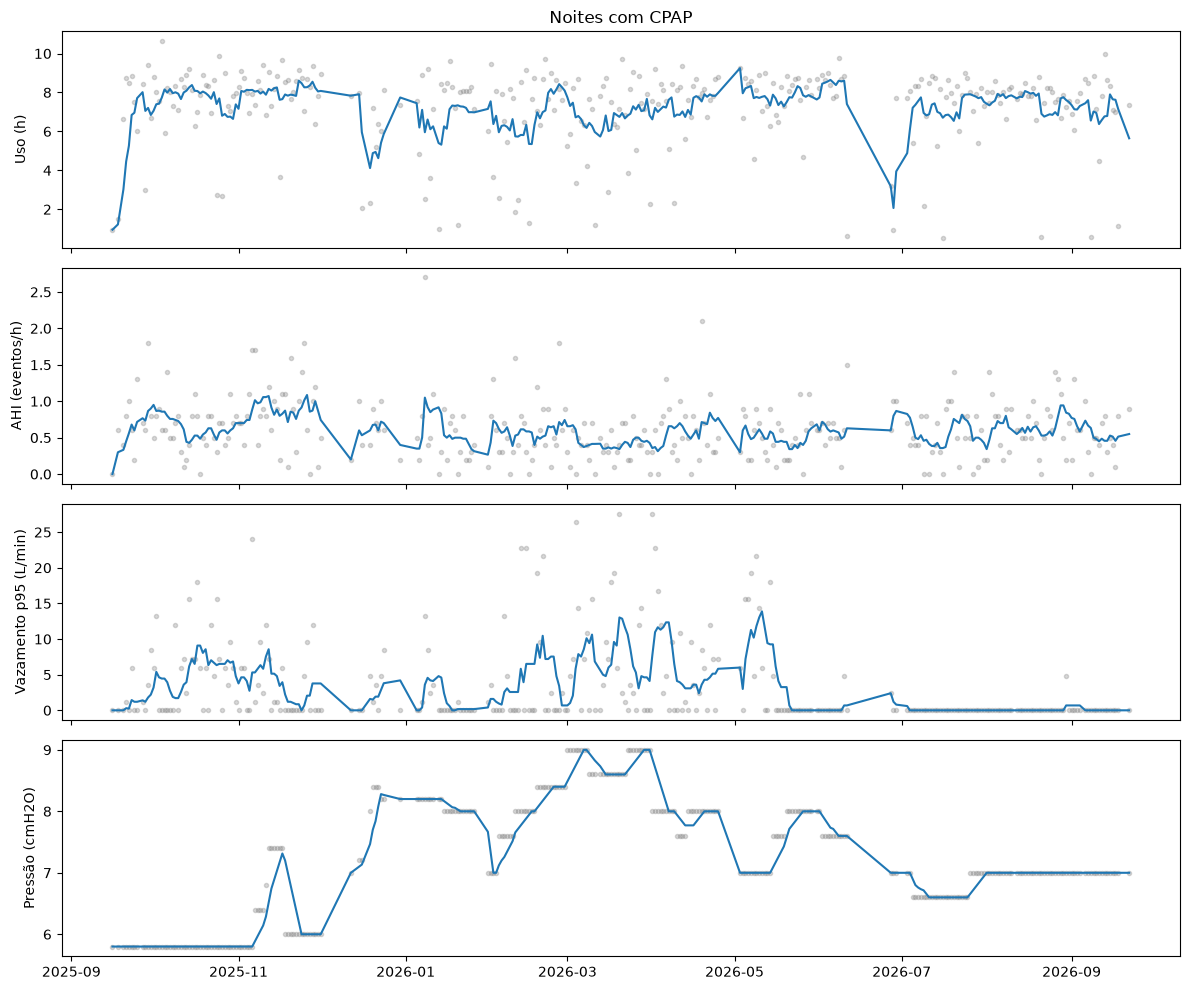

In [3]:
metrics = {
    "usage_hours": "Uso (h)",
    "ahi": "AHI (eventos/h)",
    "leak_95_l_min": "Vazamento p95 (L/min)",
    "pressure": "Pressão (cmH2O)",
}
series = nights.set_index("night")

fig, axes = plt.subplots(len(metrics), 1, figsize=(12, 10), sharex=True)
for ax, (column, title) in zip(axes, metrics.items()):
    ax.plot(series.index, series[column], ".", alpha=0.3, color="gray")
    ax.plot(series.index, series[column].rolling("7D").mean(), color="tab:blue")
    ax.set_ylabel(title)
    if study.surgery_date is not None:
        ax.axvline(study.surgery_date, color="tab:red", linestyle="--")
axes[0].set_title("Noites com CPAP")
fig.tight_layout()

## Linha de base antes da cirurgia

Últimas noites antes da cirurgia (ou até hoje, enquanto `surgeryDate` estiver vazio em `config/study.json`), só com a pressão atual. Noites com menos de 4 h de uso ficam de fora.

In [4]:
MIN_USAGE_HOURS = 4
before = nights[(nights["period"] == "before") & (nights["usage_hours"] >= MIN_USAGE_HOURS)]
current_pressure = before["pressure"].iloc[-1]
baseline = before[before["pressure"] == current_pressure].tail(study.baseline_nights)

baseline_metrics = ["usage_hours", "ahi", "oai", "cai", "hi", "leak_50_l_min", "leak_95_l_min", "resp_rate_50", "tid_vol_50", "min_vent_50", "mask_events"]
print(
    f"{len(baseline)} noites a {current_pressure} cmH2O, "
    f"de {baseline['night'].min():%d/%m/%Y} a {baseline['night'].max():%d/%m/%Y}"
)
baseline[baseline_metrics].describe(percentiles=[0.25, 0.5, 0.75]).T[["mean", "25%", "50%", "75%", "max"]].round(2)

60 noites a 7.0 cmH2O, de 09/05/2026 a 22/09/2026


,mean,25%,50%,75%,max
usage_hours,7.71,7.32,7.86,8.23,9.98
ahi,0.62,0.40,0.60,0.82,1.40
oai,0.19,0.10,0.20,0.30,0.60
cai,0.10,0.00,0.00,0.20,0.60
hi,0.29,0.10,0.20,0.40,0.80
leak_50_l_min,0.02,0.00,0.00,0.00,1.20
leak_95_l_min,1.08,0.00,0.00,0.00,21.60
resp_rate_50,17.20,16.95,17.20,17.40,18.60
tid_vol_50,0.41,0.40,0.40,0.42,0.46
min_vent_50,7.29,7.00,7.38,7.50,8.75


## Eventos e sinais detalhados (noites com DATALOG)

Eventos por hora de uso e sinais de 2 s que não existem no resumo diário: ronco e limitação de fluxo.

,mean,50%,max
night,2026-05-04 16:24:46.451613,2026-04-22 00:00:00,2026-09-22 00:00:00
hours,7.732151,7.933333,9.95
obstructive_per_hour,0.185108,0.140515,0.659341
central_per_hour,0.156425,0.122449,0.976744
hypopnea_per_hour,0.278364,0.240964,1.383648
arousal_per_hour,0.118841,0.0,1.117021
snore_fraction,0.004265,0.002937,0.030471
flow_limitation_fraction,0.131151,0.12952,0.265795
flow_limitation_95,0.052842,0.05,0.18


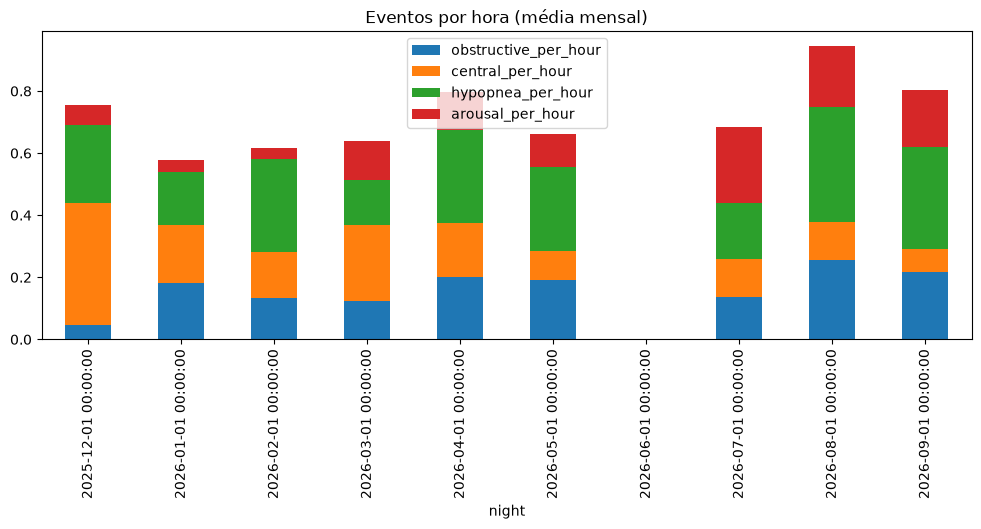

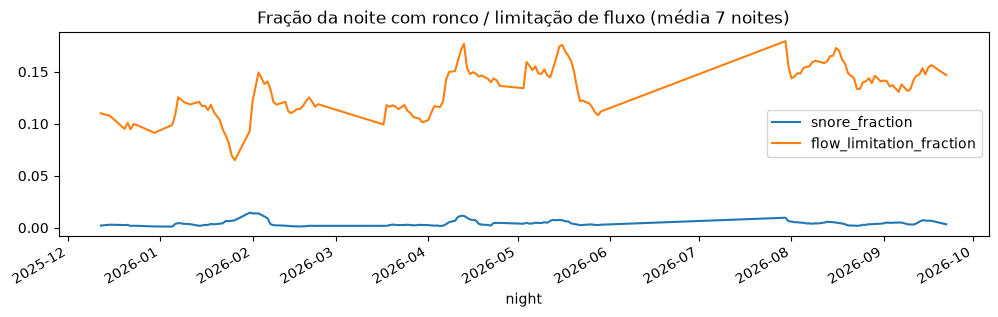

In [5]:
detail = db.sql("""
    WITH usage AS (
        SELECT night, sum(duration_min) / 60 AS hours FROM sessions GROUP BY 1
    ),
    event_counts AS (
        SELECT night, event_type, count(*) AS n FROM events GROUP BY 1, 2
    ),
    signal_stats AS (
        SELECT
            night,
            avg(CASE WHEN snore > 0 THEN 1 ELSE 0 END) AS snore_fraction,
            avg(CASE WHEN flow_limitation > 0 THEN 1 ELSE 0 END) AS flow_limitation_fraction,
            quantile_cont(flow_limitation, 0.95) AS flow_limitation_95
        FROM signals_2s
        GROUP BY 1
    )
    SELECT
        u.night,
        u.hours,
        coalesce(sum(e.n) FILTER (WHERE e.event_type = 'obstructive_apnea'), 0) / u.hours AS obstructive_per_hour,
        coalesce(sum(e.n) FILTER (WHERE e.event_type = 'central_apnea'), 0) / u.hours AS central_per_hour,
        coalesce(sum(e.n) FILTER (WHERE e.event_type = 'hypopnea'), 0) / u.hours AS hypopnea_per_hour,
        coalesce(sum(e.n) FILTER (WHERE e.event_type = 'arousal'), 0) / u.hours AS arousal_per_hour,
        s.snore_fraction,
        s.flow_limitation_fraction,
        s.flow_limitation_95
    FROM usage u
    LEFT JOIN event_counts e USING (night)
    LEFT JOIN signal_stats s USING (night)
    WHERE u.hours >= 4
    GROUP BY u.night, u.hours, s.snore_fraction, s.flow_limitation_fraction, s.flow_limitation_95
    ORDER BY u.night
""").df()

detail.set_index("night")[["obstructive_per_hour", "central_per_hour", "hypopnea_per_hour", "arousal_per_hour"]].resample("MS").mean().plot(
    kind="bar", stacked=True, figsize=(12, 4), title="Eventos por hora (média mensal)"
)
detail.set_index("night")[["snore_fraction", "flow_limitation_fraction"]].rolling("7D").mean().plot(
    figsize=(12, 3), title="Fração da noite com ronco / limitação de fluxo (média 7 noites)"
)
detail.describe().T[["mean", "50%", "max"]].round(3)